# Renewable variability and electricity price risk

Electricity demand changes throughout the day, while wind and solar output follow different patterns. I examine how their combination relates to prices in Spain and whether recent measurements can identify a high-price hour six hours ahead.

The analysis uses the public 2015–2018 electricity and weather dataset.

In [7]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT / "renewable-risk"
if not (ROOT / "src").exists():
    raise FileNotFoundError("Open this notebook from the project folder.")
sys.path.insert(0, str(ROOT))
(ROOT / "outputs").mkdir(exist_ok=True)

from src.download import download_data
from src.data import validate_and_prepare, add_risk_indicators, build_features
from src.analysis import describe_data
from src.models import train_and_evaluate, bootstrap_comparison, grouped_importance, alarm_tradeoffs
from src.figures import (plot_overview, plot_profiles, plot_regimes, plot_performance,
                         plot_errors, plot_importance, plot_decisions, plot_case)

def show_figure(path):
    display(Image(filename=str(path)))

In [8]:
manifest = download_data(ROOT)
print("Source:", manifest["dataset_page"])
print("Verified HTTP status:", manifest["http_status"])
print("Archive size:", f'{manifest["archive_bytes"] / 1_000_000:.2f} MB')
for name, item in manifest["files"].items():
    print(name, f'{item["bytes"] / 1_000_000:.2f} MB')

Source: https://www.kaggle.com/datasets/nicholasjhana/energy-consumption-generation-prices-and-weather
Verified HTTP status: 200
Archive size: 4.00 MB
energy_dataset.csv 6.27 MB
weather_features.csv 19.92 MB


In [9]:
frame, quality, validation_details = validate_and_prepare(ROOT)
display(quality)
print("Weather cities:", ", ".join(validation_details["cities"]))
print("Hourly coverage:", validation_details["electricity_start_utc"], "to", validation_details["electricity_end_utc"])

,Check,Count
0,Electricity rows,35064
1,Weather rows,178396
2,Duplicate city-hour rows,3076
3,Missing load_mw,36
4,Missing wind_mw,18
5,Missing solar_mw,18
6,Missing price_eur_mwh,0
7,Out-of-range weather temp,0
8,Out-of-range weather wind_speed,2
9,Out-of-range weather humidity,0


Weather cities: Barcelona, Bilbao, Madrid, Seville, Valencia
Hourly coverage: 2014-12-31 23:00:00+00:00 to 2018-12-31 22:00:00+00:00


residual load, a training-based high-price threshold, and a descriptive risk index. 

The index combines the historical percentile ranks of residual load, price, and absolute hourly price change with weights 0.45, 0.45, and 0.10. 

High-price threshold: 73.53 EUR/MWh
High-pressure threshold: 25.22 GW


,hours,load_gw,wind_gw,solar_gw,renewable_share,price,high_price_rate,compound_rate
year,,,,,,,,
2015,8728,28.356,5.482,1.457,0.246,61.376,0.156,0.106
2016,8779,28.508,5.416,1.406,0.242,47.440,0.044,0.035
2017,8758,28.857,5.381,1.496,0.240,59.325,0.126,0.079
2018,8758,29.064,5.584,1.373,0.240,63.438,0.181,0.102


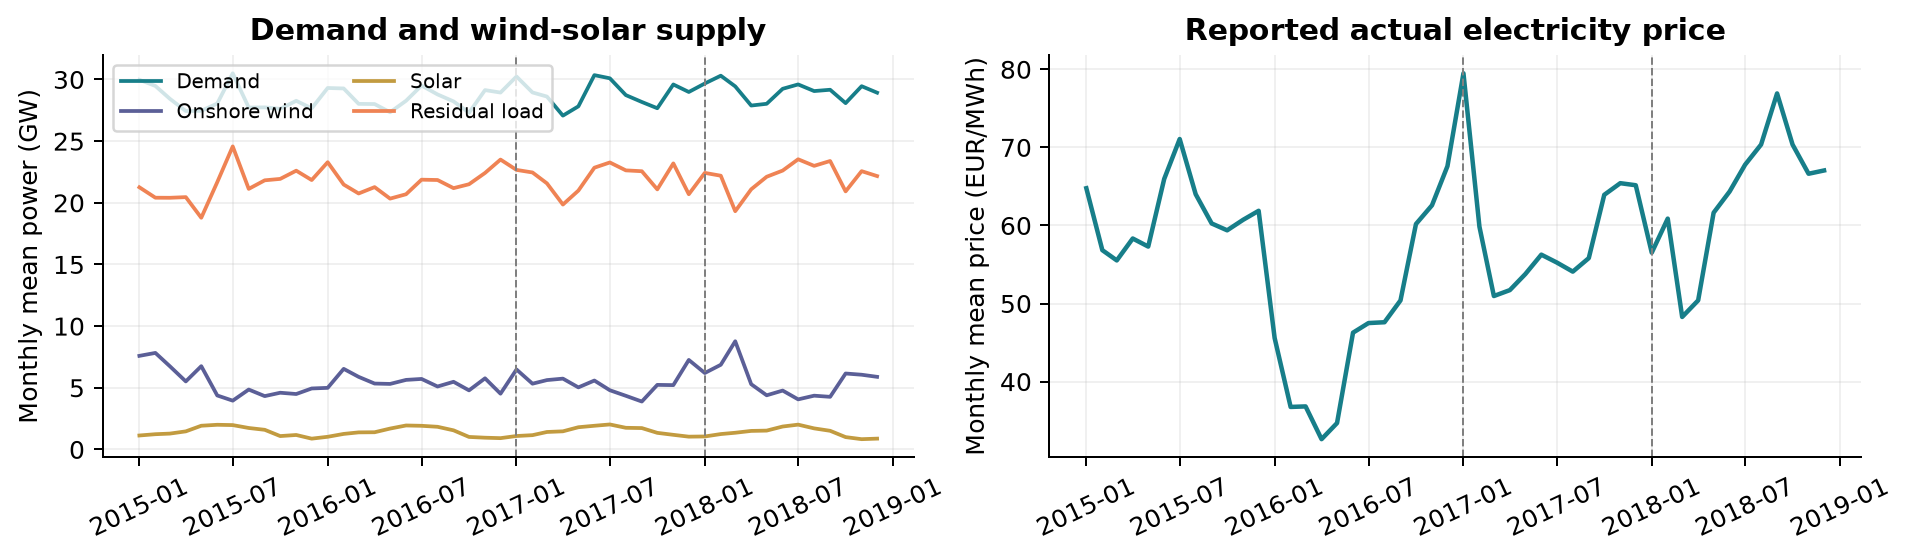

In [10]:
frame, risk_thresholds = add_risk_indicators(frame)
frame.to_csv(ROOT / "data" / "processed" / "hourly_data.csv", index_label="timestamp")
(ROOT / "outputs" / "risk_thresholds.json").write_text(json.dumps(risk_thresholds, indent=2) + "\n")
print("High-price threshold:", f'{risk_thresholds["price_q90"]:.2f} EUR/MWh')
print("High-pressure threshold:", f'{risk_thresholds["residual_q75"] / 1000:.2f} GW')
annual, regimes = describe_data(frame, risk_thresholds, ROOT)
display(annual.round(3))
show_figure(plot_overview(frame, ROOT))

Average daily patterns and four combinations of demand and wind-solar output in 2018. The grouping thresholds come from 2015–2016. 

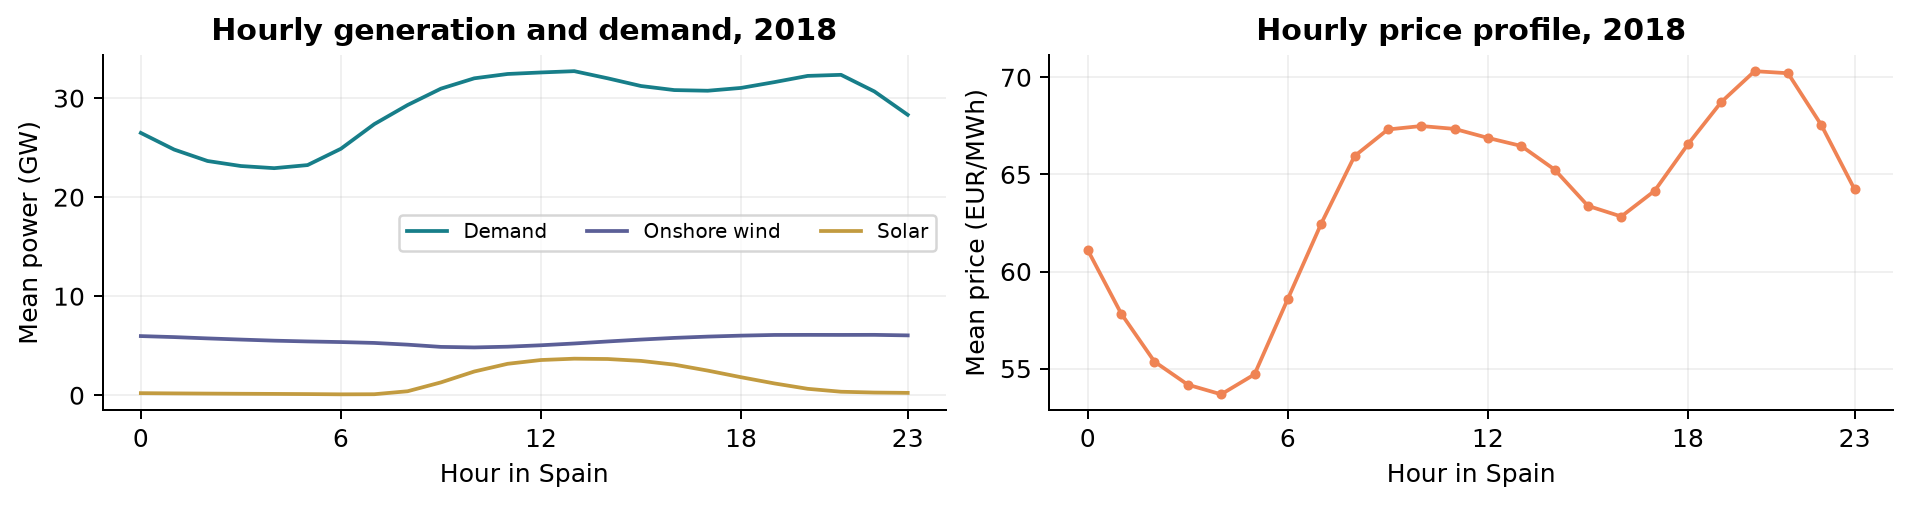

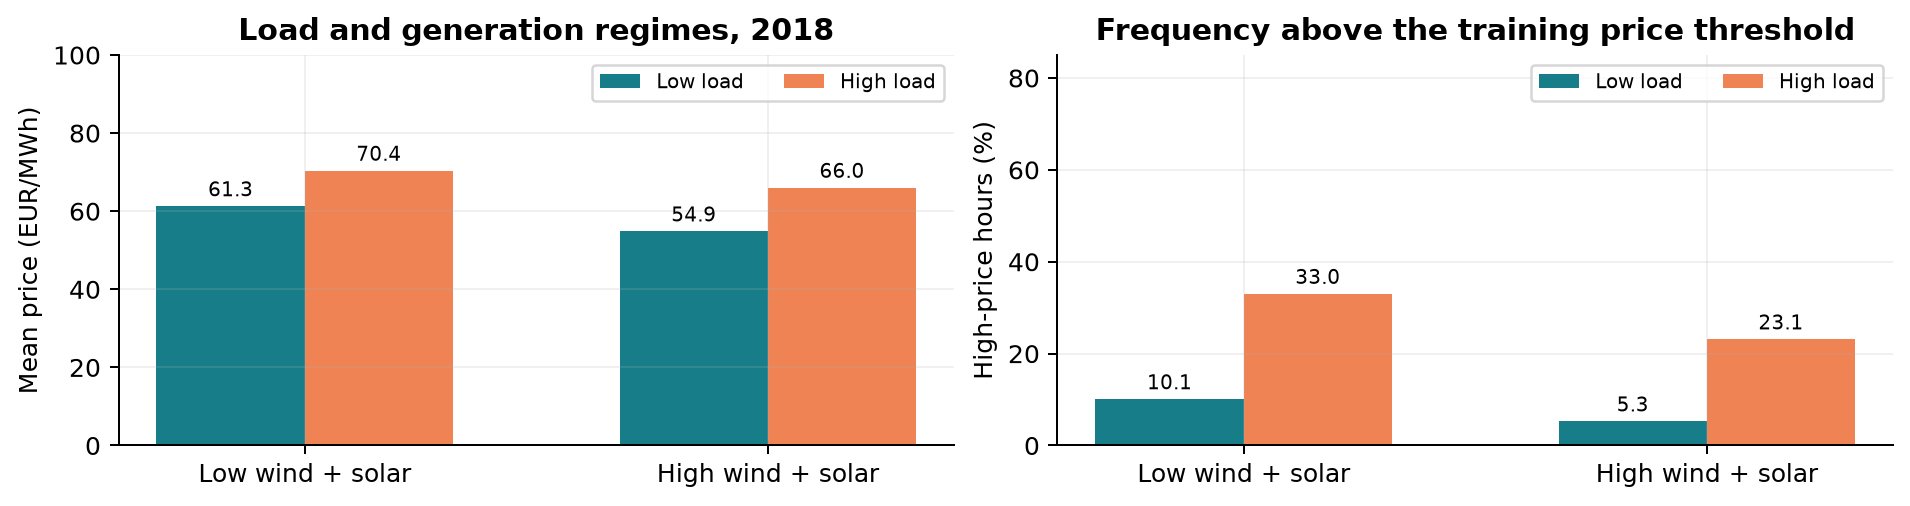

In [11]:
show_figure(plot_profiles(frame, ROOT))
show_figure(plot_regimes(regimes, ROOT))

prediction


In [12]:
features, feature_groups = build_features(frame, horizon=6)
result = train_and_evaluate(features, feature_groups, ROOT)
display(result["splits"][["Split", "Origins", "Events", "Event_rate"]].round(3))
print("Predictor count:", sum(len(columns) for columns in feature_groups.values()))
print("Model selected by validation average precision:", result["selected"])

Fitted Calendar logistic
Fitted Price + calendar
Fitted Full logistic
Fitted Full forest
Fitted Full boosting
Fitted Boosting without weather
Fitted Boosting without renewables


,Split,Origins,Events,Event_rate
0,train,17370,1701,0.098
1,validation,8754,1108,0.127
2,test,8754,1587,0.181


Predictor count: 31
Model selected by validation average precision: Full boosting


,Model,Split,Threshold,AP,ROC_AUC,Brier,Precision,Recall,F1
0,Calendar logistic,validation,0.12,0.288,0.753,0.102,0.251,0.595,0.353
1,Calendar logistic,test,0.12,0.368,0.749,0.142,0.348,0.577,0.434
2,Price + calendar,validation,0.35,0.842,0.967,0.044,0.762,0.768,0.765
3,Price + calendar,test,0.35,0.740,0.909,0.087,0.699,0.616,0.655
4,Full logistic,validation,0.29,0.849,0.970,0.043,0.727,0.828,0.774
5,Full logistic,test,0.29,0.761,0.917,0.084,0.677,0.683,0.680
6,Full forest,validation,0.24,0.862,0.966,0.042,0.729,0.829,0.776
7,Full forest,test,0.24,0.705,0.905,0.086,0.537,0.807,0.645
8,Full boosting,validation,0.26,0.874,0.969,0.040,0.805,0.784,0.794
9,Full boosting,test,0.26,0.618,0.888,0.101,0.596,0.644,0.619


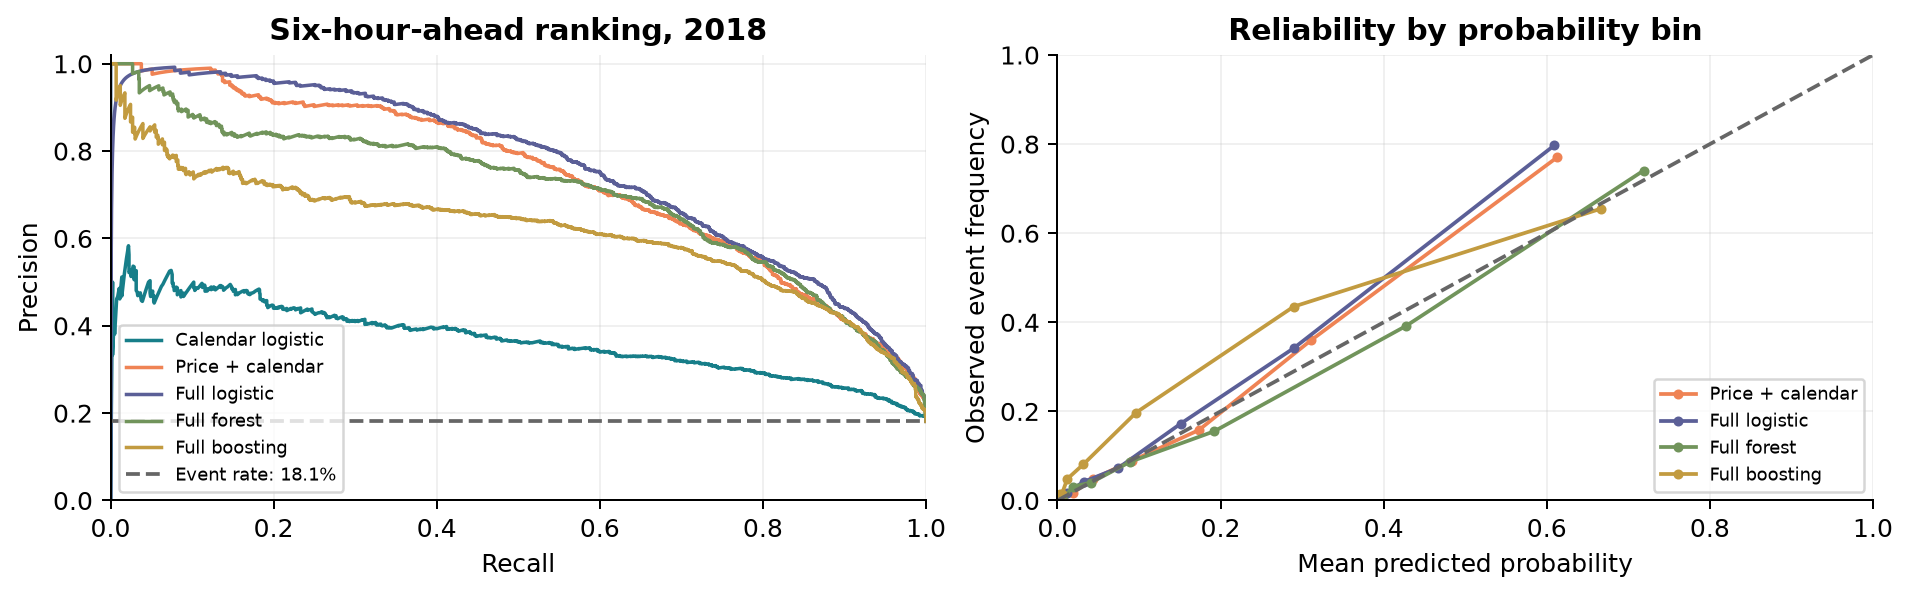

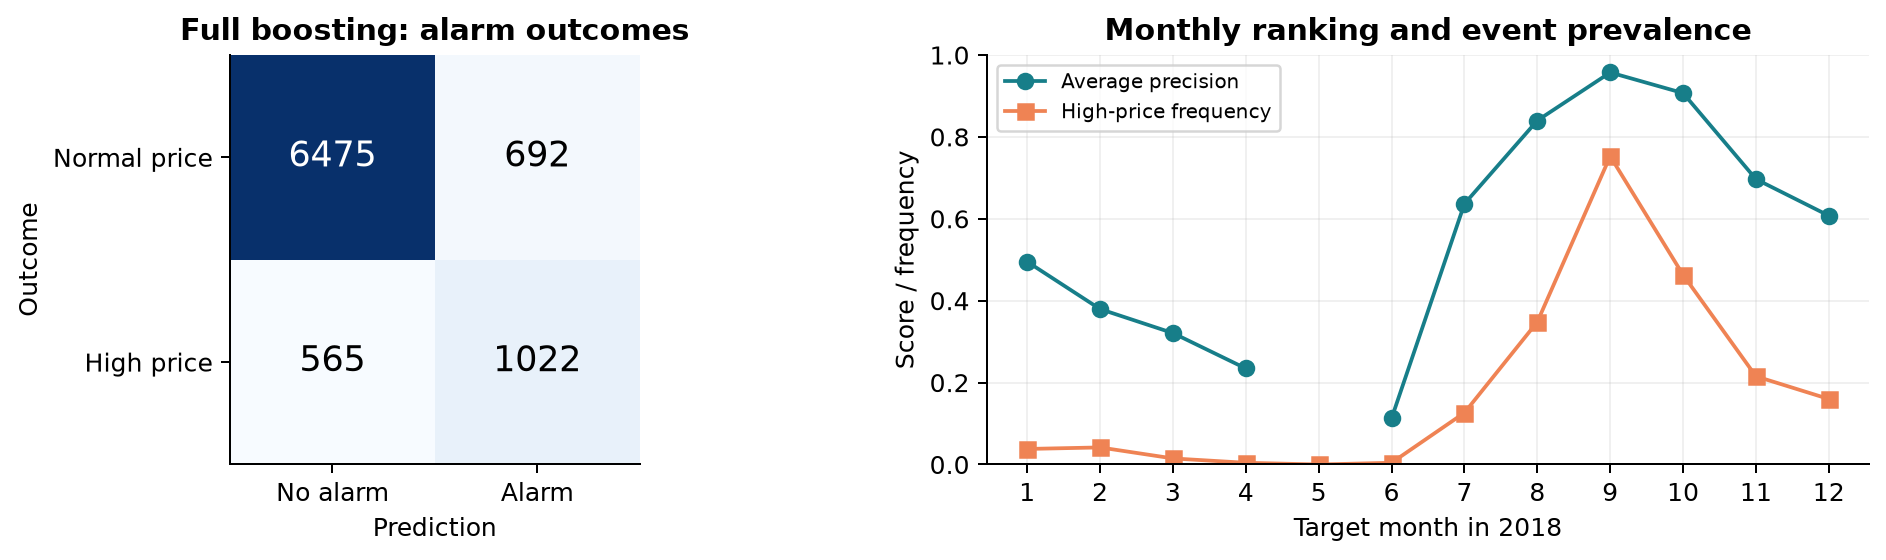

In [13]:
metrics = result["metrics"]
display(metrics[["Model", "Split", "Threshold", "AP", "ROC_AUC", "Brier", "Precision", "Recall", "F1"]].round(3))
show_figure(plot_performance(result, ROOT))
show_figure(plot_errors(result, ROOT))

Compare with the baseline

,Quantity,Estimate,Lower_95,Upper_95
0,Selected model AP,0.618,0.519,0.707
1,Price + calendar AP,0.740,0.621,0.800
2,Paired AP difference,-0.122,-0.209,-0.018


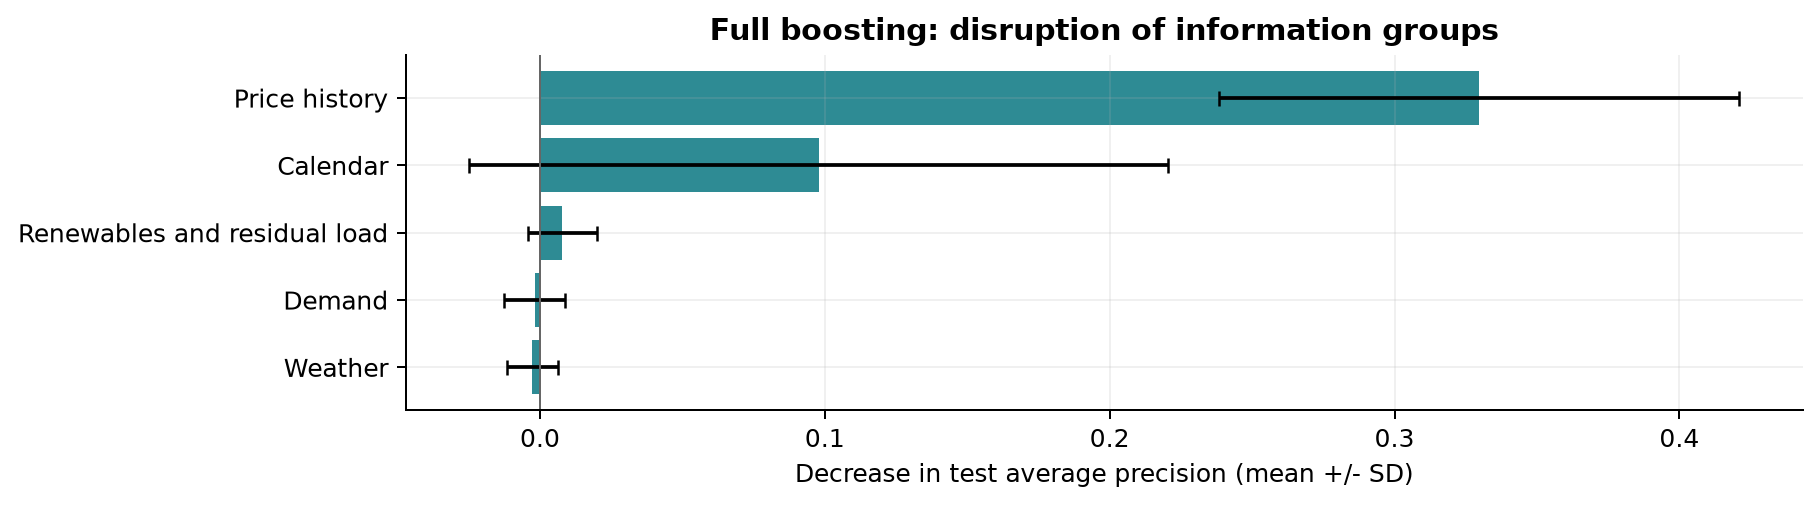

In [14]:
bootstrap = bootstrap_comparison(result, ROOT, repetitions=250)
display(bootstrap.round(3))
importance = grouped_importance(result, ROOT, repetitions=10)
show_figure(plot_importance(importance, ROOT))

How alarm policies change when a missed high-price event receives a larger relative cost than a false alarm. 

,Miss_cost_ratio,Threshold,Test_relative_loss,False_alarms_per_1000,Misses_per_1000,Alarm_rate,Recall
0,1,0.44,0.141,45.236,95.956,0.131,0.471
1,3,0.17,0.250,111.263,46.150,0.246,0.745
2,5,0.10,0.323,152.844,34.042,0.300,0.812
3,10,0.06,0.427,200.708,22.618,0.359,0.875
4,20,0.04,0.577,239.205,16.907,0.404,0.907


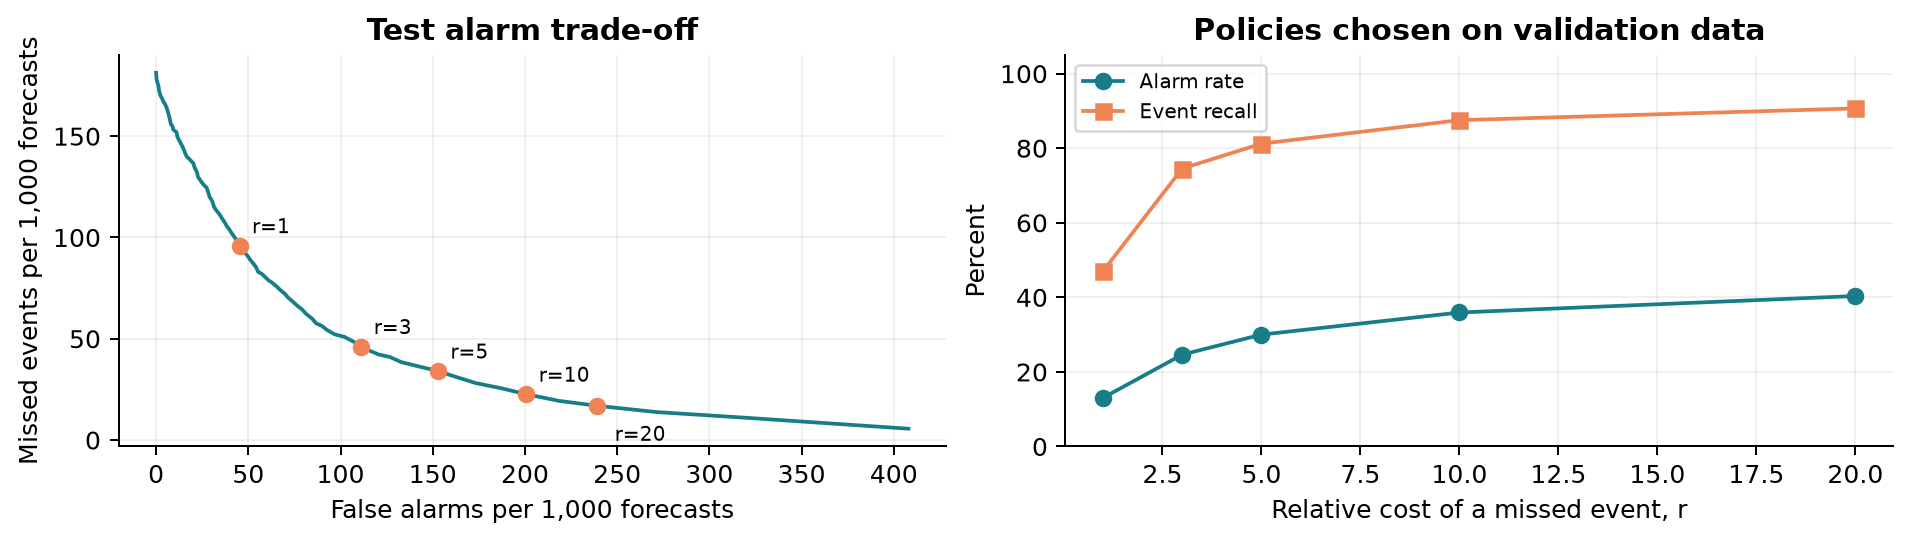

In [15]:
threshold_curve, decisions = alarm_tradeoffs(result, ROOT)
display(decisions.round(3))
show_figure(plot_decisions(threshold_curve, decisions, ROOT))

The earliest seven-day window with the largest number of high-price hours in 2018. 

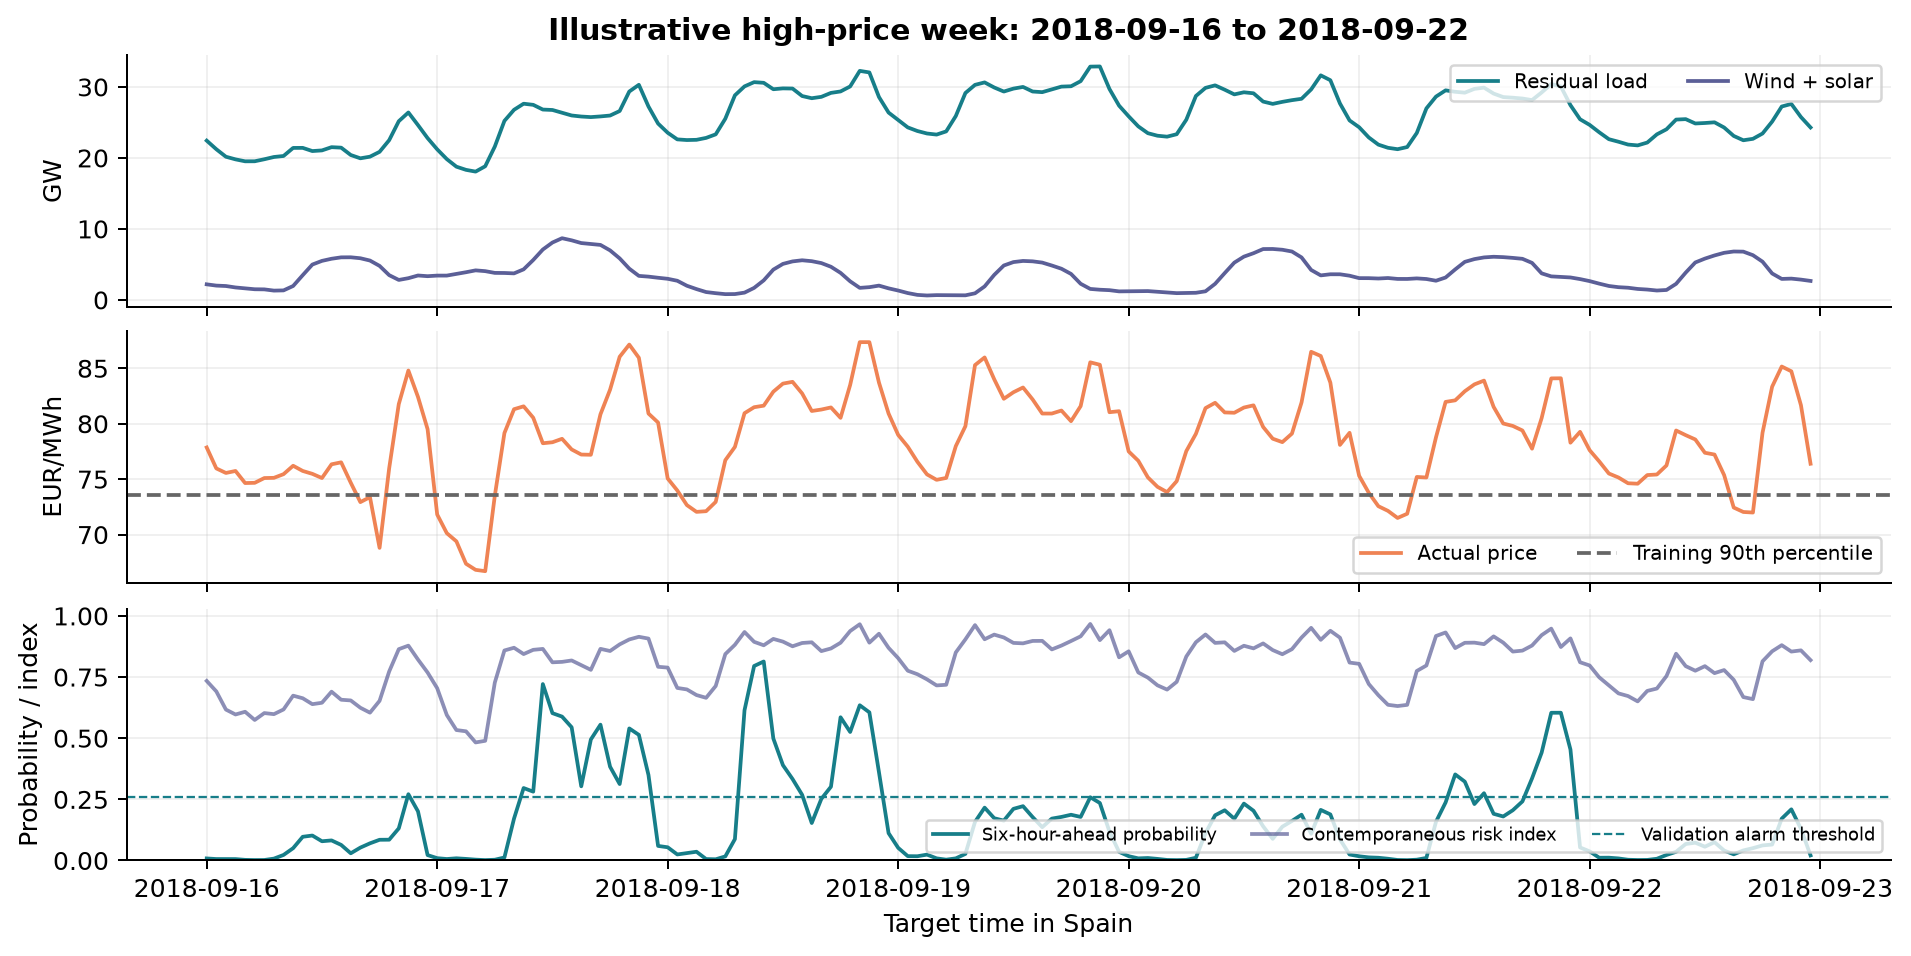

Forecasts saved: 8754
Alarms at the validation F1 threshold: 1714


In [16]:
show_figure(plot_case(frame, result, ROOT))
print("Forecasts saved:", len(result["predictions"]))
print("Alarms at the validation F1 threshold:", int(result["predictions"]["alarm"].sum()))
from src.report_tables import main as write_report_tables
write_report_tables(ROOT)